<a href="https://colab.research.google.com/github/CarlosMDSN/ml-campus_data_project-python/blob/main/CampusDatasetProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Campus Database Project


## Data Preparation

In [17]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
import pandas as pd

##Load the Dataset

In [19]:
df= pd.read_csv(
    '/content/drive/MyDrive/Colab Notebooks/CampusWalkDataset_TemplateIDs(Sheet1).csv',
    skiprows=4
)

Inspect the dataset structure

In [20]:
print('Column names \n')
print(df.shape)
print('\nSample rows\n')
print(df.head())

Column names 

(994, 27)

Sample rows

  recorder_id       date                        location        weather  \
0     R26_001  9/22/2026                L01 MainEntrance  Partly cloudy   
1     R26_001  9/22/2026                L02 LibraryGreen          Sunny   
2     R26_001  9/22/2026   L06 HedgingBehindSportsCentre  Partly cloudy   
3     R26_001  9/22/2026  L08 AccessRoadNearSportsCentre  Partly cloudy   
4     R26_001  9/22/2026   L06 HedgingBehindSportsCentre          Sunny   

  temperature_c sound level foot_traffic primary_sound_type_urban  \
0            16       Quiet          Low             Human voices   
1            16    Moderate          Low                  Traffic   
2            16       Quiet          Low             Construction   
3            16    Moderate          Low             Human voices   
4            16    Moderate          Low                  Traffic   

  other_sound_type_urban primary_sound_type_nature  ...    wellbeing_rating  \
0               

## Cleaning Empty Cells

## Identifying categorial dimensions

In [21]:
# Print all columns to understand what aspects we can compare
print("Dataset Columns:\n", df.columns.tolist())

# Look at unique values of key categorical columns for comparison ideas
for col in ['location', 'weather', 'sound level', 'foot_traffic', 'wellbeing_rating', 'stress_rating']:
    if col in df.columns:
        print(f"\nUnique values in '{col}' (Top 10):\n", df[col].value_counts().head(10))


Dataset Columns:
 ['recorder_id', 'date', 'location', 'weather', 'temperature_c', 'sound level', 'foot_traffic', 'primary_sound_type_urban', 'other_sound_type_urban', 'primary_sound_type_nature', 'other_sound_type_nature', 'insects_count', 'birds_count', 'trees_presence', 'native_or_wild_plant_presence', 'ornnamental_or_planted_plant_presence', 'moss_or_lichen_presence', 'wellbeing_rating', 'ease_rating', 'stress_rating', 'nature_connection_experience_rating', 'most_notable_nature_element', 'other_notes', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26']

Unique values in 'location' (Top 10):
 location
L06 HedgingBehindSportsCentre     27
L01 MainEntrance                  23
L05 GreenFrontSportsCentre        19
L04 PathFrontiHub                 18
L07 CarParkNearSportsCentre       15
L02 LibraryGreen                  14
L03 LowerSidePathiHub              9
L08 AccessRoadNearSportsCentre     7
L10 OtherOffCampus                 3
Name: count, dtype: int64

Unique values in 'we

After reviewing the Dataset, we can see that during the collection of data that most participants felt **Positive** and **Calm**.

## Visual Graph on Wellbeing & Stress level.

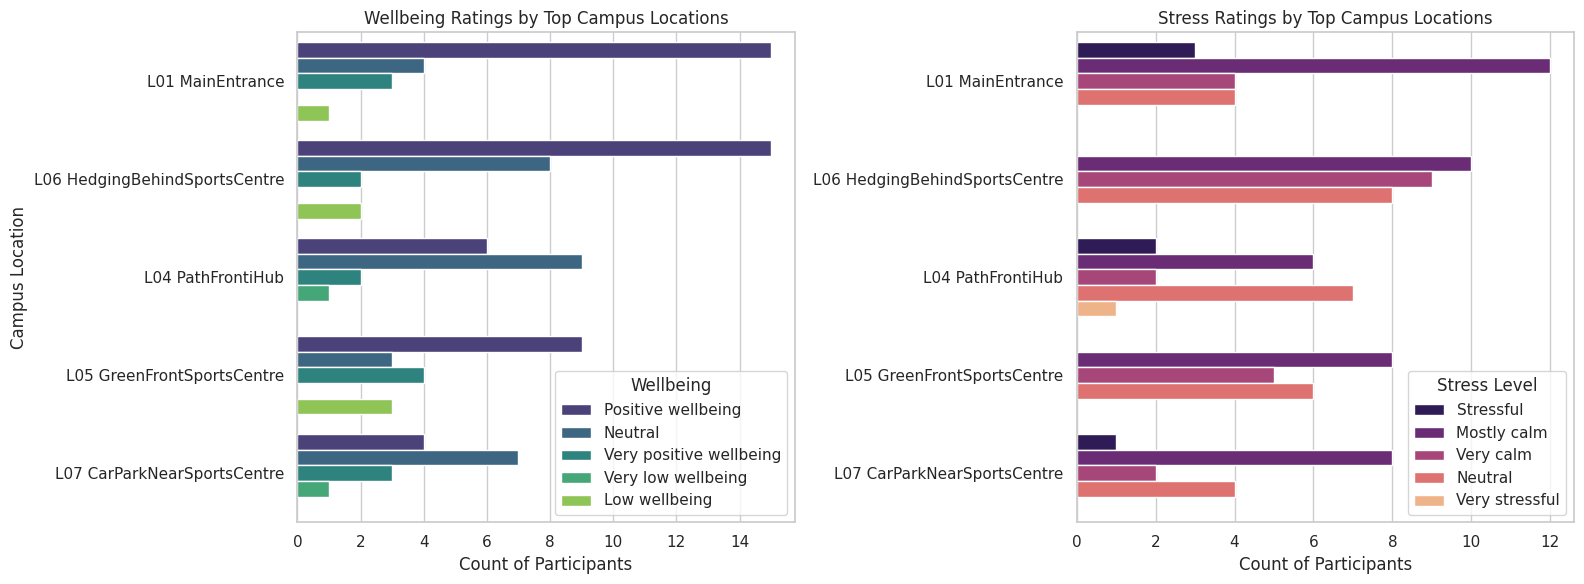

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter out missing values for these key comparison columns
vis_df = df.dropna(subset=['location', 'wellbeing_rating', 'stress_rating']).copy()

# Focus on the most visited campus locations
top_locations = vis_df['location'].value_counts().head(5).index
filtered_vis_df = vis_df[vis_df['location'].isin(top_locations)]

# Set style
sns.set_theme(style="whitegrid")

# Create a side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Wellbeing Ratings by Location
sns.countplot(
    data=filtered_vis_df,
    y='location',
    hue='wellbeing_rating',
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Wellbeing Ratings by Top Campus Locations')
axes[0].set_xlabel('Count of Participants')
axes[0].set_ylabel('Campus Location')
axes[0].legend(title='Wellbeing')

# 2. Stress Ratings by Location
sns.countplot(
    data=filtered_vis_df,
    y='location',
    hue='stress_rating',
    palette='magma',
    ax=axes[1]
)
axes[1].set_title('Stress Ratings by Top Campus Locations')
axes[1].set_xlabel('Count of Participants')
axes[1].set_ylabel('')
axes[1].legend(title='Stress Level')

plt.tight_layout()
plt.show()

Here we can see a **Side-by-side Bar Chart** showing the distribution of Wellbeing and Stress ratings across the top locations in the dataset.

### Analyzing the Impact of Weather on Wellbeing and Stress Levels

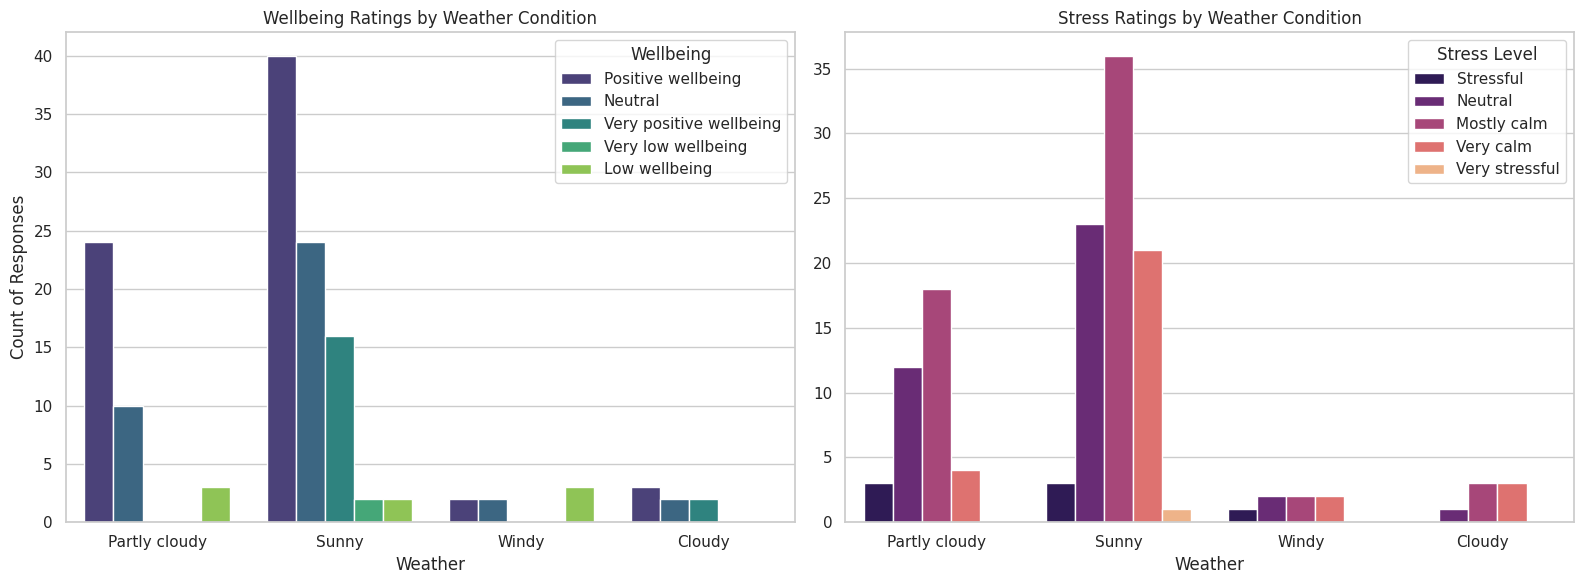

In [23]:
# Clean up casing for the weather column to group them correctly
weather_df = df.dropna(subset=['weather', 'wellbeing_rating', 'stress_rating']).copy()
weather_df['weather'] = weather_df['weather'].str.strip().str.capitalize()

# Create a side-by-side visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Weather vs. Wellbeing Rating
sns.countplot(
    data=weather_df,
    x='weather',
    hue='wellbeing_rating',
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Wellbeing Ratings by Weather Condition')
axes[0].set_xlabel('Weather')
axes[0].set_ylabel('Count of Responses')
axes[0].legend(title='Wellbeing')

# 2. Weather vs. Stress Rating
sns.countplot(
    data=weather_df,
    x='weather',
    hue='stress_rating',
    palette='magma',
    ax=axes[1]
)
axes[1].set_title('Stress Ratings by Weather Condition')
axes[1].set_xlabel('Weather')
axes[1].set_ylabel('')
axes[1].legend(title='Stress Level')

plt.tight_layout()
plt.show()

In [24]:
# Let's look at the average temperature recorded for each weather type
# and see if there is an objective difference we can report.
weather_df['temperature_c'] = pd.to_numeric(weather_df['temperature_c'], errors='coerce')
temp_summary = weather_df.groupby('weather')['temperature_c'].mean().reset_index()
print("Average Temperature (C) by Weather Condition:")
display(temp_summary)

Average Temperature (C) by Weather Condition:


,weather,temperature_c
0,Cloudy,15.200000
1,Partly cloudy,16.514286
2,Sunny,16.908451
3,Windy,11.750000


### Summary of Weather Comparison Insights

Based on the analysis of the graphs and temperature averages, we can draw the following conclusions:
1. **The Temperature Gap**: Windy weather is the coldest condition in our dataset, averaging **11.75°C**, which is over **5°C colder** than sunny days (averaging **16.91°C**).
2. **The Mood-Weather Connection**:
   * **Sunny** weather strongly correlates with high **Positive** and **Very positive** wellbeing, alongside **Calm** stress ratings.
   * **Partly cloudy** weather acts very similarly to sunny weather, showing that full sunshine isn't required to feel relaxed on a walk.
   * **Windy** and **cold weather** conditions show a visible shift toward **Low wellbeing** ratings, highlighting how physical discomfort from wind and lower temperatures directly influences participants' environmental experiences.

### Decision Log

### Week 6 15/10/2026


| Item | Details |
|-------|---------|
| Issue or Challenge Identified ||
| Decision Taken | |
| Justification | |
| Evidence Supporting the Decision | |
| Reflection | |


In [25]:
# define the mapping dictionary
sound_mapping = {
    'Quiet': 0,
    'Moderate': 1,
    'Loud': 2
}

# create a new numerical column for the encoded values
df['sound_level_encoded'] = df['sound level'].map(sound_mapping)

# verify mapping and check data types
print("--- Mapping Verification ---")
print(df[['sound level', 'sound_level_encoded']]
       .drop_duplicates()
       .reset_index(drop=True)
       )

--- Mapping Verification ---
  sound level  sound_level_encoded
0       Quiet                  0.0
1    Moderate                  1.0
2        Loud                  2.0
3         NaN                  NaN


### Ordinal Encoding & Spearman Rank Correlation Matrix

Since the sensory and psychological measurements (wellbeing, stress, sound, foot traffic) are ordinal categories, I will first clean the completely empty trailing rows from the dataframe, map these categories to an ordered numeric scale, and then compute a Spearman rank correlation matrix to see how these factors are mathematically related.

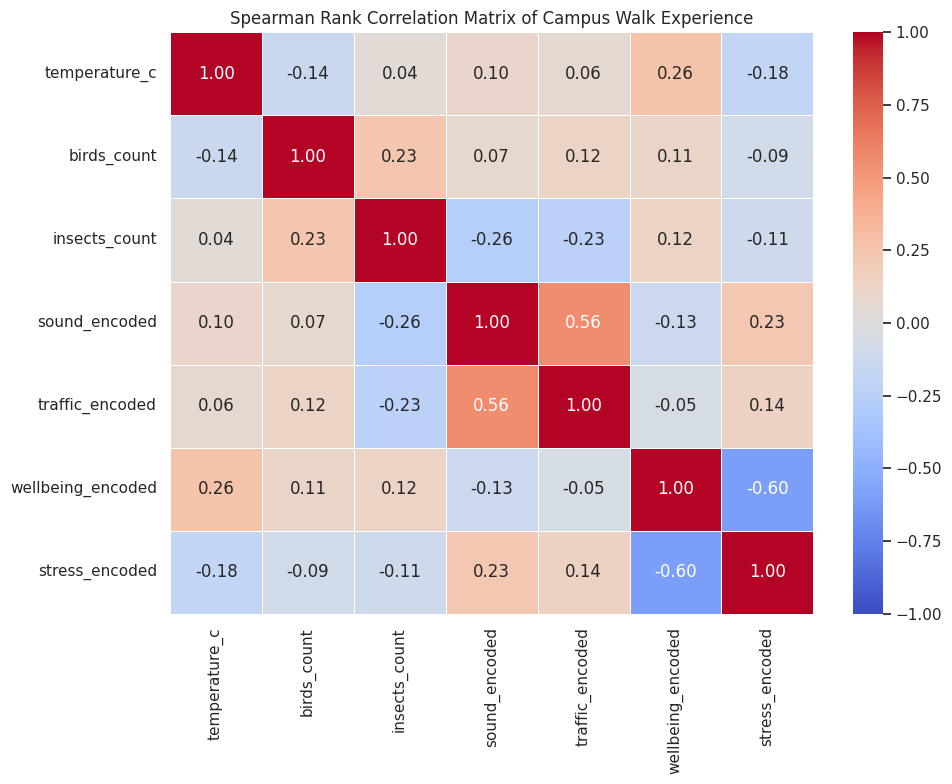

In [26]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Clean up dataset: Keep only rows where we actually have a recorder_id or a wellbeing rating
corr_df = df.dropna(subset=['recorder_id', 'wellbeing_rating']).copy()

# 2. Convert temperature to numeric
corr_df['temperature_c'] = pd.to_numeric(corr_df['temperature_c'], errors='coerce')

# 3. Convert biological counts to numeric
corr_df['birds_count'] = pd.to_numeric(corr_df['birds_count'], errors='coerce').fillna(0)
corr_df['insects_count'] = pd.to_numeric(corr_df['insects_count'], errors='coerce').fillna(0)

# 4. Map ordinal categorical columns to logical numeric scales
wellbeing_map = {
    'Very low wellbeing': 0,
    'Low wellbeing': 1,
    'Neutral': 2,
    'Positive wellbeing': 3,
    'Very positive wellbeing': 4
}

stress_map = {
    'Very calm': 0,
    'Mostly calm': 1,
    'Neutral': 2,
    'Stressful': 3,
    'Very stressful': 4
}

sound_map = {
    'Quiet': 0,
    'Moderate': 1,
    'Loud': 2
}

traffic_map = {
    'low': 0,
    'Low': 0,
    'Moderate': 1,
    'High': 2
}

# Apply the mappings
corr_df['wellbeing_encoded'] = corr_df['wellbeing_rating'].map(wellbeing_map)
corr_df['stress_encoded'] = corr_df['stress_rating'].map(stress_map)
corr_df['sound_encoded'] = corr_df['sound level'].map(sound_map)
corr_df['traffic_encoded'] = corr_df['foot_traffic'].map(traffic_map)

# Select numerical/ordinal columns for correlation
columns_to_correlate = [
    'temperature_c',
    'birds_count',
    'insects_count',
    'sound_encoded',
    'traffic_encoded',
    'wellbeing_encoded',
    'stress_encoded'
]

# Compute Spearman Rank Correlation (ideal for ordinal/ranked data)
correlation_matrix = corr_df[columns_to_correlate].corr(method='spearman')

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)
plt.title('Spearman Rank Correlation Matrix of Campus Walk Experience')
plt.tight_layout()
plt.show()

 ### Summary of correlation matrix

 1. **Wellbeing VS Stress**: There is a strong negative correlation (-0.60) between wellbeing and stress. This statistical result tells us exactly what we'd expect, as stress levels go down, wellbeing ratings go up significantly. It validates that the scales used by the participants are consistent.

 2. **The Urban Impact**: There is a strong poositive correlation (0.56) between noise levels and foot traffic. This proves that high-traffic areas on campus directly drive the sound volume up, bringing more urban noise pollution.

3. **Environment & Mood**: There is a mild positive correlation (0.26) between temperature and wellbeing. This indicates that warmer weather on campus is generally linked to higher wellbeing ratings, while coldr days tend to drag the mood down slighlty

4. **No direct Impact from biodiversity**: The correlation values for bird and insect counts with wellbeing/stress are close to zero. This suggests that simply having birds or insects nearby does not automatically make walkers feel calmer or happier, other environmental factors like noise level and crowding play a much larger role.

### What Nature Elements Do Walkers Notice Most?

Here I will analyse the`most_notable_nature_element` to find out what specific elements of the campus environment captured mine and my classmates attention during our walks.

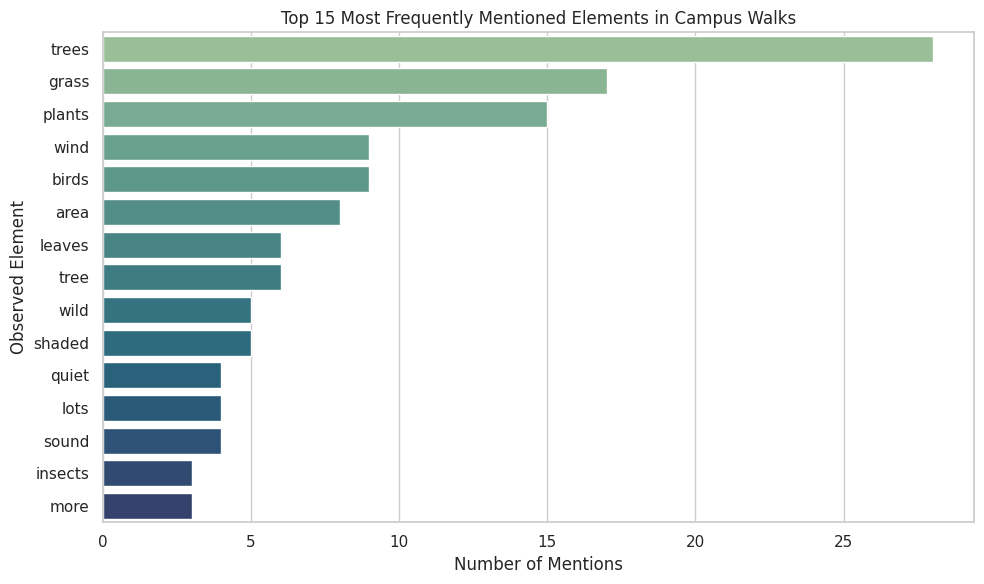

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re

# Filter out missing records
text_df = df.dropna(subset=['most_notable_nature_element']).copy()

# Helper to tokenize and clean words
def clean_and_tokenize(text):
    # Convert to lowercase and remove punctuation
    text = re.sub(r'[^a-zA-Z\s]', '', str(text).lower())
    words = text.split()
    # Exclude common small words (stopwords)
    stopwords = {'and', 'the', 'a', 'of', 'in', 'on', 'with', 'at', 'to', 'for', 'or', 'is', 'are', 'was', 'very', 'some', 'few'}
    return [w for w in words if w not in stopwords]

# Combine and count all words
all_words = []
for text in text_df['most_notable_nature_element']:
    all_words.extend(clean_and_tokenize(text))

word_counts = Counter(all_words)
common_words_df = pd.DataFrame(word_counts.most_common(15), columns=['Word', 'Frequency'])

# Visualize top noted elements
plt.figure(figsize=(10, 6))
sns.barplot(data=common_words_df, x='Frequency', y='Word', palette='crest', hue='Word', legend=False)
plt.title('Top 15 Most Frequently Mentioned Elements in Campus Walks')
plt.xlabel('Number of Mentions')
plt.ylabel('Observed Element')
plt.tight_layout()
plt.show()